# Makeing scatter and probability density function (pdf) plots of magnetization and energy for Monte Carlo and RBM generated configurations

Kai Zhang, The University of Texas at Tyler, 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load data (two columns)

e_dict = {}
m_dict = {}

for T in np.arange(0.6, 1.6001, 0.05):
    data = np.loadtxt('./q2L32_gen_pcd10lr0.0001epoch5000/gen_ME_q2L32T{:.3f}.txt'.format(T))
    m_dict[round(T, 3)] = data[:, 0]
    e_dict[round(T, 3)] = data[:, 1]

In [3]:
m_dict[0.6]

array([1.        , 0.99804688, 0.99414062, ..., 0.99804688, 0.99804688,
       0.99804688], shape=(20000,))

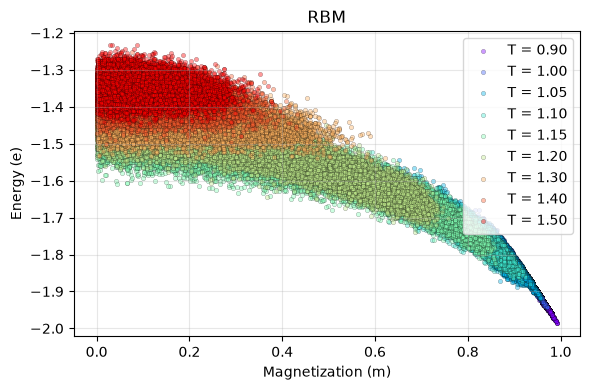

In [4]:
T_list = [0.9, 1.0, 1.05, 1.1, 1.15, 1.2, 1.3, 1.4, 1.5]

# Different colors
colors = plt.cm.rainbow(np.linspace(0, 1, len(T_list)))

plt.figure(figsize=(6, 4))

for T, color in zip(T_list, colors):
    plt.scatter(
        m_dict[T],
        e_dict[T],
        s=10,
        alpha=0.4,
        color=color,
        edgecolors='black',
        linewidths=0.3,
        label=f'T = {T:.2f}'
    )

plt.xlabel('Magnetization (m)')
plt.ylabel('Energy (e)')
plt.title('RBM')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
MCe_dict = {}
MCm_dict = {}

for T in np.arange(0.6, 1.6001, 0.05):
    data = np.loadtxt('../Potts_q2/configs_wolff_eq20000f100/mc_ME_q2L32T{:.3f}.txt'.format(T))
    MCm_dict[round(T, 3)] = data[:, 0]
    MCe_dict[round(T, 3)] = data[:, 1]

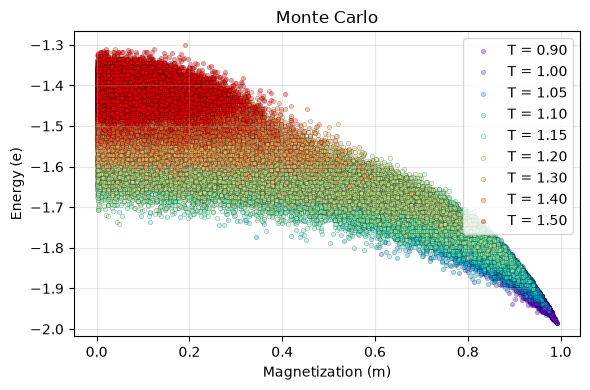

In [6]:
colors = plt.cm.rainbow(np.linspace(0, 1, len(T_list)))

plt.figure(figsize=(6, 4))

for T, color in zip(T_list, colors):
    plt.scatter(
        MCm_dict[T],
        MCe_dict[T],
        s=10,
        alpha=0.4,
        color=color,
        edgecolors='black',
        linewidths=0.3,
        label=f'T = {T:.2f}'
    )

plt.xlabel('Magnetization (m)')
plt.ylabel('Energy (e)')
plt.title('Monte Carlo')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

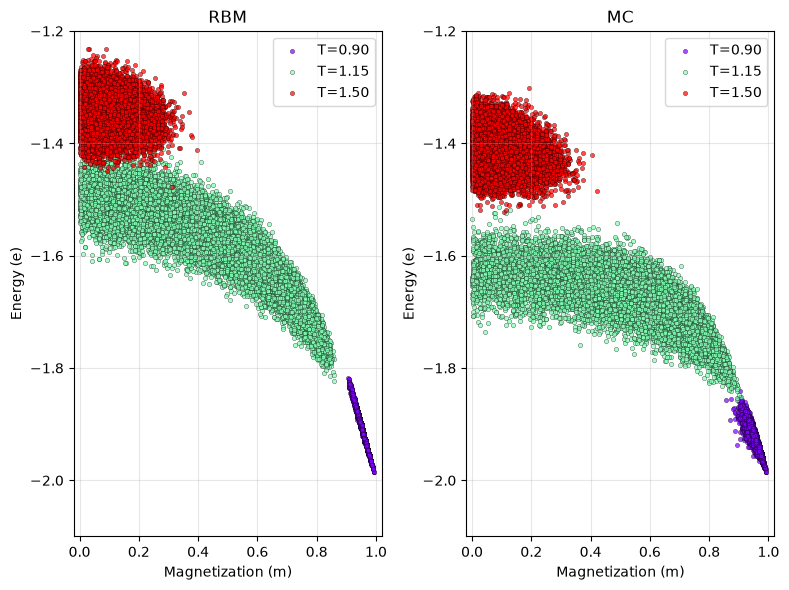

In [7]:
#i = 4
#T, color  = T_list[i], colors[i]

fig, axes = plt.subplots(1, 2, figsize=(8, 6))

for T, color in zip([T_list[0],T_list[4],T_list[8]], [colors[0],colors[4],colors[8]]):
    axes[0].scatter(m_dict[T], e_dict[T], s=10, alpha=0.7, color=color, edgecolors='black', linewidths=0.3, label=f'T={T:.2f}')
    axes[0].set_xlim(-0.02, 1.02)
    axes[0].set_ylim(-2.1, -1.2)
    axes[0].set_xlabel('Magnetization (m)')
    axes[0].set_ylabel('Energy (e)')
    axes[0].set_title('RBM')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].scatter(MCm_dict[T], MCe_dict[T], s=10, alpha=0.7, color=color, edgecolors='black', linewidths=0.3,label=f'T={T:.2f}')
    axes[1].set_xlim(-0.02, 1.02)
    axes[1].set_ylim(-2.1, -1.2)
    axes[1].set_xlabel('Magnetization (m)')
    axes[1].set_ylabel('Energy (e)')
    axes[1].set_title('MC')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
from scipy.stats import gaussian_kde

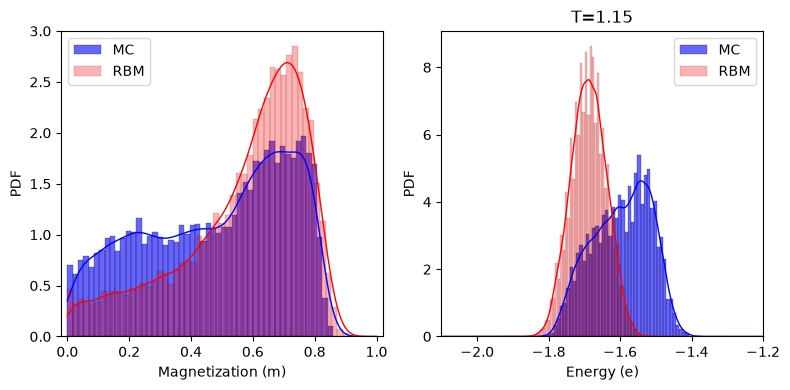

In [9]:
i = 4
T = T_list[i]
color = colors[i]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

x = np.linspace(0, 1, 1000)
axes[0].set_xlim(-0.02, 1.02)
axes[0].hist(m_dict[T], bins=50, density=True, alpha=0.6, color='b', edgecolor='black', linewidth=0.3, label='MC')
kde = gaussian_kde(m_dict[T])
axes[0].plot(x, kde(x), color='b', linewidth=1)

axes[0].hist(MCm_dict[T], bins=50, density=True, alpha=0.3, color='r', edgecolor='black', linewidth=0.3, label='RBM')
kde = gaussian_kde(MCm_dict[T])
axes[0].plot(x, kde(x), color='r', linewidth=1)
axes[0].set_xlabel('Magnetization (m)')
axes[0].set_ylabel('PDF')
axes[0].legend()

x = np.linspace(-2.1, -1.2, 1000)
axes[1].set_xlim(-2.1, -1.2)
axes[1].hist(e_dict[T], bins=50, density=True, alpha=0.6, color='b', edgecolor='black', linewidth=0.3, label='MC')
kde = gaussian_kde(e_dict[T])
axes[1].plot(x, kde(x), color='b', linewidth=1)

axes[1].hist(MCe_dict[T], bins=50, density=True, alpha=0.3, color='r', edgecolor='black', linewidth=0.3, label='RBM')
kde = gaussian_kde(MCe_dict[T])
axes[1].plot(x, kde(x), color='r', linewidth=1)
axes[1].set_xlabel('Energy (e)')
axes[1].set_ylabel('PDF')
axes[1].legend()
axes[1].set_title(f'T={T:.2f}')

plt.tight_layout()
plt.show()